In [2]:

# IMPORTS

# pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

# pip install tensorflow
import tensorflow as tf
import keras
from keras import layers

In [3]:
df = pd.read_csv('lego_sets.csv')

df.dtypes

ages                     str
list_price           float64
num_reviews          float64
piece_count          float64
play_star_rating     float64
prod_desc                str
prod_id              float64
prod_long_desc           str
review_difficulty        str
set_name                 str
star_rating          float64
theme_name               str
val_star_rating      float64
country                  str
dtype: object

In [4]:
df['ages'].value_counts()
# Separate this column to only show minAge

ages
6-12     1476
7-14     1421
8-14     1180
4-7       957
5-12      911
10+       870
2-5       840
7-12      723
9-14      624
16+       420
8-12      350
4-99      311
12+       298
6-14      233
8+        226
1½-3      213
14+       212
10-21     184
6+        148
10-16     148
1½-5      113
9-16       92
5+         71
11-16      66
9-12       46
12-16      42
4+         21
9+         21
5-8        21
10-14      21
7+          2
Name: count, dtype: int64

In [5]:
# This code is 98% claude
# The primary function is to separate the 'ages' column into two different columns - min and max ages

import re

def parse_min_age(age_str):
    if pd.isna(age_str):
        return None

    age_str = str(age_str).strip()
    age_str = age_str.replace('½', '.5')  # handle fractions like 1½ -> 1.5

    # Grab the first number in the string. This covers "12+", "12-16", and "2".
    match = re.search(r'\d*\.?\d+', age_str)
    return float(match.group()) if match else None

df['min_age'] = df['ages'].apply(parse_min_age)



In [6]:
df

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,country,min_age
0,6-12,29.9900,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,Average,Bird Island Egg Heist,4.5,Angry Birds™,4.0,US,6.0
1,6-12,19.9900,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,Easy,Piggy Plane Attack,5.0,Angry Birds™,4.0,US,6.0
2,6-12,12.9900,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,Easy,Piggy Car Escape,4.3,Angry Birds™,4.1,US,6.0
3,12+,99.9900,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,Average,United States Capitol Building,4.6,Architecture,4.3,US,12.0
4,12+,79.9900,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,Challenging,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,US,12.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12256,7-14,36.5878,6.0,341.0,4.4,Protect NINJAGO® City from flying Manta Ray Bo...,70609.0,Help Cole save Shen-Li in this cool THE LEGO® ...,Easy,Manta Ray Bomber,4.3,THE LEGO® NINJAGO® MOVIE™,4.2,PT,7.0
12257,7-14,24.3878,8.0,217.0,4.1,Stop a Piranha Attack with Kai and Misako!,70629.0,Play out an action-packed Piranha Mech pursuit...,Easy,Piranha Attack,3.6,THE LEGO® NINJAGO® MOVIE™,4.1,PT,7.0
12258,7-14,24.3878,18.0,233.0,4.6,Stop a crime in the NINJAGO® City street market!,70607.0,"Team up with Lloyd Garmadon, Nya and Officer T...",Easy,NINJAGO® City Chase,4.6,THE LEGO® NINJAGO® MOVIE™,4.5,PT,7.0
12259,6-14,12.1878,1.0,48.0,5.0,Achieve Spinjitzu greatness with the Green Ninja!,70628.0,Learn all the skills of Spinjitzu with THE LEG...,Very Easy,Lloyd - Spinjitzu Master,5.0,THE LEGO® NINJAGO® MOVIE™,5.0,PT,6.0


In [7]:
df['country'].unique()

<StringArray>
['US', 'AU', 'AT', 'BE', 'CA', 'CH', 'CZ', 'DE', 'DN', 'ES', 'FI', 'FR', 'GB',
 'IE', 'IT', 'LU', 'NO', 'NL', 'NZ', 'PL', 'PT']
Length: 21, dtype: str

In [8]:
country_to_continent = {
    'US': 'North America',
    'CA': 'North America',
    'AU': 'Oceania',
    'NZ': 'Oceania',
    'AT': 'Europe',
    'BE': 'Europe',
    'CH': 'Europe',
    'CZ': 'Europe',
    'DE': 'Europe',
    'DN': 'Europe',   
    'ES': 'Europe',
    'FI': 'Europe',
    'FR': 'Europe',
    'GB': 'Europe',
    'IE': 'Europe',
    'IT': 'Europe',
    'LU': 'Europe',
    'NO': 'Europe',
    'NL': 'Europe',
    'PL': 'Europe',
    'PT': 'Europe',
}

df['continent'] = df['country'].map(country_to_continent)
df = df.drop('country', axis=1)

In [9]:
# Separate the 'continent' column to it's own columns

df = pd.get_dummies(df, columns=['continent'], dtype=int)
df.head()

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,min_age,continent_Europe,continent_North America,continent_Oceania
0,6-12,29.99,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,Average,Bird Island Egg Heist,4.5,Angry Birds™,4.0,6.0,0,1,0
1,6-12,19.99,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,Easy,Piggy Plane Attack,5.0,Angry Birds™,4.0,6.0,0,1,0
2,6-12,12.99,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,Easy,Piggy Car Escape,4.3,Angry Birds™,4.1,6.0,0,1,0
3,12+,99.99,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,Average,United States Capitol Building,4.6,Architecture,4.3,12.0,0,1,0
4,12+,79.99,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,Challenging,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,12.0,0,1,0


In [10]:
df.columns

Index(['ages', 'list_price', 'num_reviews', 'piece_count', 'play_star_rating',
       'prod_desc', 'prod_id', 'prod_long_desc', 'review_difficulty',
       'set_name', 'star_rating', 'theme_name', 'val_star_rating', 'min_age',
       'continent_Europe', 'continent_North America', 'continent_Oceania'],
      dtype='str')

In [11]:
# dropping unnessary columns
droppables = ['ages', 'prod_desc', 'prod_long_desc', 'theme_name', 'set_name', 'prod_id', 'continent_Oceania']
df = df.drop(droppables, axis=1)

In [12]:
df = df.dropna() # Drops 1/10th of the data so not too bad

In [13]:
# df.isna().sum() # Lots of NAs, trying KNNimputer for now

# from sklearn.impute import KNNImputer

# imputer = KNNImputer(n_neighbors=5)

# df = pd.DataFrame(
#     imputer.fit_transform(df),
#     columns=df.columns,
#     index=df.index
# )

# int_cols = ['review_difficulty'] 
# df[int_cols] = df[int_cols].round().astype(int)

In [14]:
# # Creating a new column 'price_per_brick' for more fun comparisons
# # Only for analytic purposes, doesn't work in ML 
# #

# df['price_per_brick'] = df['piece_count'] / df['list_price']
# df['price_per_brick'] = df['price_per_brick'].round(2)
# df['price_per_brick']



In [15]:
df = df.drop_duplicates()


In [16]:
df['review_difficulty'].unique()

<StringArray>
['Average', 'Easy', 'Challenging', 'Very Easy', 'Very Challenging']
Length: 5, dtype: str

In [17]:
# Mapping the review_difficulty column
review_mapper = {'Very Easy': 0, 'Easy': 1, 'Average': 2, 'Challenging': 3, 'Very Challenging': 4}
df['review_difficulty'] = df['review_difficulty'].map(review_mapper)


In [18]:
correlations = df.corr()
correlations

# List price and piece count correlate heavily with each other as expected. This will definitely cause some high R-scores.

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,min_age,continent_Europe,continent_North America
list_price,1.000000,0.458342,0.870460,-0.007092,0.501707,0.001588,-0.049172,0.538730,0.087585,-0.108633
num_reviews,0.458342,1.000000,0.553689,-0.064145,0.324569,0.009173,0.025902,0.560600,0.032257,-0.037008
piece_count,0.870460,0.553689,1.000000,-0.011595,0.550285,0.074289,0.071886,0.675289,0.044003,-0.052228
play_star_rating,-0.007092,-0.064145,-0.011595,1.000000,0.050826,0.627790,0.496680,-0.190224,0.001058,-0.003490
review_difficulty,0.501707,0.324569,0.550285,0.050826,1.000000,0.057631,0.068131,0.529181,0.042538,-0.048890
star_rating,0.001588,0.009173,0.074289,0.627790,0.057631,1.000000,0.740524,0.052782,-0.001416,-0.002722
val_star_rating,-0.049172,0.025902,0.071886,0.496680,0.068131,0.740524,1.000000,0.040217,-0.009505,0.009224
min_age,0.538730,0.560600,0.675289,-0.190224,0.529181,0.052782,0.040217,1.000000,0.036109,-0.038862
continent_Europe,0.087585,0.032257,0.044003,0.001058,0.042538,-0.001416,-0.009505,0.036109,1.000000,-0.697586
continent_North America,-0.108633,-0.037008,-0.052228,-0.003490,-0.048890,-0.002722,0.009224,-0.038862,-0.697586,1.000000


## NN STARTS HERE

In [ ]:
df.head()

# Just a sanity check that it's all ML-ready :)

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,min_age,continent_Europe,continent_North America
0,29.99,2.0,277.0,4.0,2,4.5,4.0,6.0,0,1
1,19.99,2.0,168.0,4.0,1,5.0,4.0,6.0,0,1
2,12.99,11.0,74.0,4.3,1,4.3,4.1,6.0,0,1
3,99.99,23.0,1032.0,3.6,2,4.6,4.3,12.0,0,1
4,79.99,14.0,744.0,3.2,3,4.6,4.1,12.0,0,1


In [ ]:
# perform X/y -split
# if you more than one independent variable, list them all here
# leave out the target variable (dependent variable)

# this is a nice and common trick => everything EXCEPT the target variable => support variables
X = df.drop("list_price", axis=1)

# have only the target variable here (dependent variable)
y = df['list_price']

In [ ]:
# in Classic ML, we only had train/test -split
# in deep learning, we usually use validation-data also, for better
# optimization possibilities and better metrics

# unfortunately the scikit-learn's train_test_split doesn't support validation
# set split in itself.

# if you want to split the test set into two for a validation set too, try this trick:

# step 1, split the data into 70% (training data) and 30% (temporary data)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3)

# step 2, split the temporary data in HALF (0.5) => 15% test and 15% validation
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5)



In [ ]:
# create neural network

# save the amount of support variables into a helper variable
# so we don't have to update the input_shape all the time
variable_amount = len(X.columns)

# Define Sequential neural network model
# input shape has to match the amount of SUPPORT VARIABLES
# in other words => amount of columns in X 
# Tip: have at least the same number of nodes as in the input shape
# output layer in regression is always 1 node without activation function
model = keras.Sequential(
    [
        layers.Dense(16, activation="relu", input_shape=(variable_amount,), ),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ]
)

# select the optimizer and loss function
# you can try rmsprop also as optimizer, or stochastic gradient descent
# loss-function for regression is mse (mean squared error)
model.compile(optimizer='adam', loss='mse')

model.summary()

c:\Users\OMISTAJA\Desktop\Uni_assignments\Deep_learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


# train/fit neural network with validation data
# see the instructions on the train/test -split above on how to split the data correctly
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_val, y_val))


Epoch 1/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 2295.8506 - val_loss: 4438.1831
Epoch 2/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2243.1711 - val_loss: 4304.0200
Epoch 3/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2246.2637 - val_loss: 4308.1006
Epoch 4/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2246.4375 - val_loss: 4554.4517
Epoch 5/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2165.9385 - val_loss: 4328.0703
Epoch 6/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2103.0322 - val_loss: 4553.4546
Epoch 7/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2120.1926 - val_loss: 4265.1509
Epoch 8/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2190.2231 - val_loss: 4369.5908
Epoch 9/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2100.2844 - val_loss: 4890.8901
Epoch 10/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2090.9766 - val_loss: 4359.6016
Epoch 11/600
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2025.24

I tried using anything from 200 to 2000 epochs. 2000 epochs had the greatest R-squared with 3 dense layers at 0.97

<Axes: >

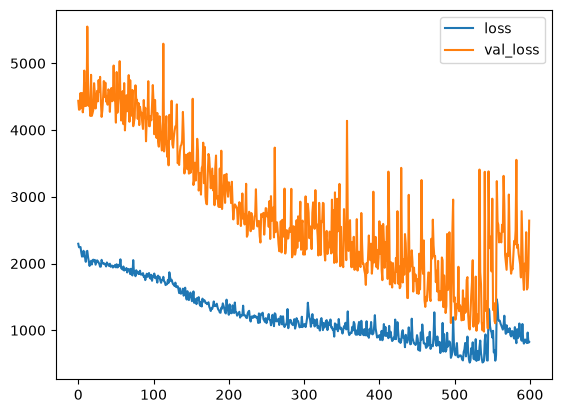

In [ ]:
# let's use pandas for this (easy code)
# try to look if the model is actually training 
# => the error is going downwards
# if using validation data, you get two lines
# in this case, see if the lines follow a similar trend 
# (they don't always overlap with complex data, the trend is more important)
loss_df = pd.DataFrame(model.history.history)
loss_df.plot()



The val_loss curve does not settle down even when trying with 2000 epochs. So the issue must be in the data. It only settles down when removing piece_count column, but then the performance of the whole model drops down. Perhaps this dataset isn't great for NN-training.

In [ ]:
# compare the final model loss/evaluation values
print("Test data evaluation:")
print(model.evaluate(X_test, y_test, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(X_train, y_train, verbose=0))



Test data evaluation:
968.5838623046875

Train data evaluation:
1021.9500122070312


In [ ]:
# get test predictions
test_predictions = model.predict(X_test)

# reshape the data for easier comparison table
test_predictions = pd.Series(test_predictions.reshape(len(y_test),))
pred_df = pd.DataFrame(np.asarray(y_test), columns=['Test True Y'])
pred_df = pd.concat([pred_df, test_predictions], axis=1)
pred_df.columns = ['Test True Y', 'Model Predictions']

# print the comparison table - true values vs. model predicted values
# we can nicely see here how far off our model is in some cases
pred_df



28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,Test True Y,Model Predictions
0,39.9900,54.574963
1,30.4980,46.855724
2,23.9520,25.089045
3,89.9900,116.465828
4,21.9478,16.187984
...,...,...
879,19.9900,23.999910
880,37.6971,27.985975
881,29.9900,31.978186
882,36.5878,47.210979


<Axes: xlabel='Test True Y', ylabel='Model Predictions'>

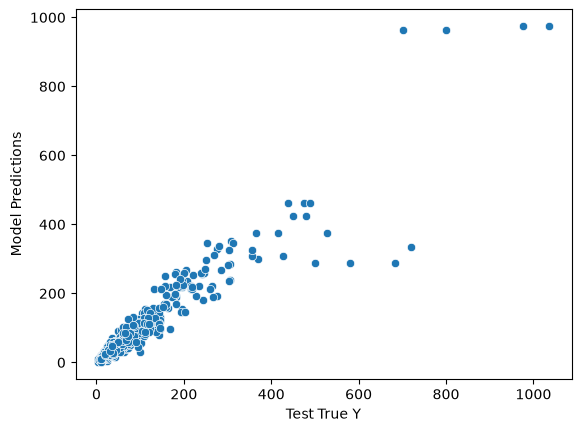

In [ ]:
# these values follow a linear diagonal line = good predictions
# we basically compare the predicted values 
# to true test values and see the differences
sns.scatterplot(x='Test True Y', y='Model Predictions', data=pred_df)

In [ ]:
# MAE - Mean average error
print("MAE")
print(round(metrics.mean_absolute_error(y_test, test_predictions), 2), "$")

# MSE - Mean square error
print("\nMSE")
print(round(metrics.mean_squared_error(y_test, test_predictions), 2), "$^2")

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(y_test, test_predictions)), 2), "$")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(y_test, test_predictions), 2))

# Explained Variance Score => 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
# high variance score = model is a good fit for the data 
# low variance score = model is not a good fit for the data
# the higher the score, the model is more able to explain the variation in the data
# if score is low, we might need more and better data
print("\nExplained variance score:")
print(round(metrics.explained_variance_score(y_test, test_predictions), 2))

MAE
13.91 $

MSE
968.58 $^2

RMSE:
31.12 $

R-squared:
0.9

Explained variance score:
0.9


I've tried using a couple different NN-structures. As the data is rather simple, I tried to use only one dense layer with 600 epochs. This made the R-squared to drop down to 0.80 from high 0.9s, so it's not a great approach. 

Some other different approaches all yield different results. For example, dropping piece_count drops the R-squared all the way to around 0.50 which is not great, so piece_count is an important column with the price. 

With one, wider dense layer the R-squared is 0.80. Two layers narrow layers and it goes to 0.64. and with three it is once again 0.94. These layers had 16, 32 and 16 nodes in respective order. With two very wide layers (32, 64) it goes to 0.94 though. However, when using the original, directly copypasted 3 layer (16, 32, 16) setup it is also at 0.94

However, there seems to be some great variance with the score when running the model multiple times. There are most likely some high quantiles in the data wrecking havoc.

<Axes: xlabel='list_price', ylabel='piece_count'>

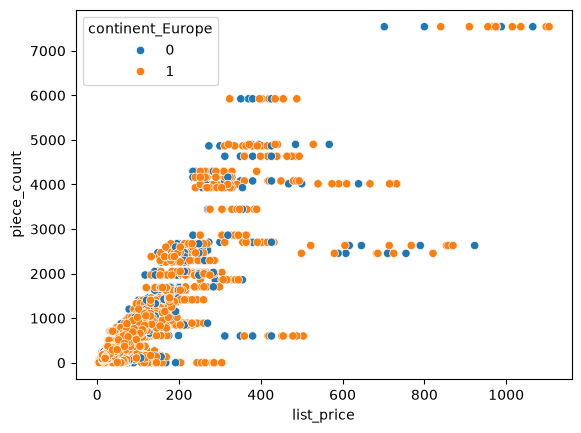

In [21]:
sns.scatterplot(data=df, x='list_price', y='piece_count', hue='continent_Europe')

As suspected, it looks like there are some outliers in the data. However, I am running out of time with this exercise so I won't be optimizing the dataset further. :( Possible optimizing methods I could use could be e.g creating some synthetic data to even out the disparity, or outright removing them.

C:\Users\OMISTAJA\AppData\Local\Temp\ipykernel_23680\2285612724.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test - test_predictions))


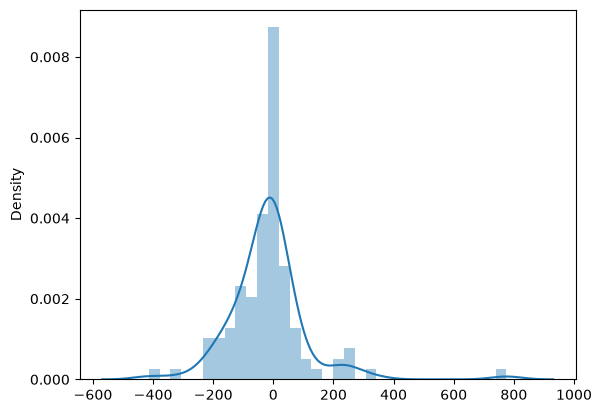

In [ ]:
# if the prediction distribution are far from normal distribution
# then the model is not probably good enough
# distplot is deprecating in future pandas-version
# unfortunately, there's no exact alternative to do this plot at the moment
sns.distplot((y_test - test_predictions))
plt.show()
plt.close()



In [ ]:
X.columns

Index(['num_reviews', 'piece_count', 'play_star_rating', 'review_difficulty',
       'star_rating', 'val_star_rating', 'min_age', 'continent_Europe',
       'continent_North America'],
      dtype='str')

In [ ]:
# let's try with some new imaginary data
# this example uses the student performance index score dataset
# modify this as needed regarding your own dataset
tester_row = {
    'num_reviews': 1534,
    'piece_count': 5500,
    'play_star_rating': 3,
    'review_difficulty': 4,
    'star_rating': 5,
    'val_star_rating': 3 ,
    'min_age': 3 ,
    'continent_Europe': 0,
    'continent_North America': 1
}

# convert to pandas-format
tester_row = pd.DataFrame([tester_row])

In [ ]:


# get the prediction from the model and print out the result
result = model.predict(tester_row)[0]

print()
print(f"Estimated cost of the lego set:")
print(f"$ {round(float(result[0]), 2)}")
print("----------------")



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step

Estimated cost of the lego set:
$ 388.92
----------------


In general it was an interesting exercise to try different NN-structures, and seeing how the model's performance changes. The data doesn't seem to be that great though, or it needs heavy optimizing as the piece count and list price columns heavily correlate with each other, but when removing either one of them the performance tanks. Maybe a different dataset would be better for this exercixe. 